In [3]:
#Loading data and packages required for batman fitting

%matplotlib inline
import sys, os, time
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import batman, emcee

from eph_pass2 import EPH
import pipeline as pl

det2 = pl.load_detrended("../data/detrended_pass2")
t_list, f_list, dy_list = pl.stack(det2)
t_all, f_all, dy_all = pl.concat_sorted(t_list, f_list, dy_list)
eph_boot = pd.read_csv("../data/ephemeris_bootstrap_pass2.csv")

In [4]:
#Step 1: Stellar density and the a/R* conversion

RHO = (8.0, 1.8)       # (value, error) in g/cm^3, from 2020 discovery paper
G = 6.674e-11

def aRs_from_rho(rho_cgs, P_days):
    rho = rho_cgs * 1000.0                   # g/cm^3 -> kg/m^3
    P = P_days * 86400.0                     # days -> seconds
    return (G * rho * P**2 / (3 * np.pi)) ** (1 / 3)

#### The data for one planet

In [5]:
#Step 2: Cut a window around each transit of planet c

name = "c"
row = eph_boot[eph_boot.planet == name].iloc[0]
P0, T00 = row.P_med, row.T0_med
T14 = EPH[name]["T14_h"] / 24
half_win = 3 * T14                                   # keep ±3 transit durations

phase = ((t_all - T00 + 0.5 * P0) % P0) - 0.5 * P0   # days from nearest mid-transit
sel = np.abs(phase) < half_win
t, f, dy = t_all[sel], f_all[sel], dy_all[sel]
print(name, "|", len(t), "points in windows | window half-width (h):", round(half_win * 24, 1))

c | 11917 points in windows | window half-width (h): 4.2


In [6]:
#Step 3: Remove the other planets’ transits from these windows

def other_planets(t, name, margin=1.3):
    m = np.zeros(len(t), dtype=bool)
    for other in ["b", "c", "d"]:
        if other == name:
            continue
        r = eph_boot[eph_boot.planet == other].iloc[0]
        half = EPH[other]["T14_h"] / 24 / 2 * margin
        ph = ((t - r.T0_med + 0.5 * r.P_med) % r.P_med) - 0.5 * r.P_med
        m |= np.abs(ph) < half
    return m

bad = other_planets(t, name)
t, f, dy = t[~bad], f[~bad], dy[~bad]
print("removed", bad.sum(), "points overlapping other planets | left:", len(t))

# If planet b’s transit lands inside c’s window, those points would look like a mysterious extra dip and bias the fit. This removes them.

removed 208 points overlapping other planets | left: 11709


#### Building the batman model

In [7]:
#Step 4: Parameters to a batman model

def make_params(theta):
    T0, P, k, b, rho, q1, q2, f0, lns = theta
    aRs = aRs_from_rho(rho, P)
    inc = np.degrees(np.arccos(b / aRs))             # inclination from b and a/R*
    sq = np.sqrt(q1)
    u1, u2 = 2 * sq * q2, sq * (1 - 2 * q2)          # Kipping q1,q2 -> quadratic u1,u2

    pm = batman.TransitParams()
    pm.t0, pm.per, pm.rp, pm.a, pm.inc = T0, P, k, aRs, inc
    pm.ecc, pm.w = 0.0, 90.0                         # circular orbit
    pm.limb_dark = "quadratic"
    pm.u = [u1, u2]
    return pm

In [8]:
#Step 5: The model function, built once

#starting guesses for k = sqrt(expected depth), from the earlier table:
#k^2 = 0.00049 (b), 0.00329 (c), 0.00069 (d)

K0 = {"b": 0.0221, "c": 0.0574, "d": 0.0262}

theta0 = np.array([T00, P0, K0[name], 0.3, RHO[0], 0.3, 0.3, 1.0, 0.0])

model_obj = batman.TransitModel(make_params(theta0), t,
                                supersample_factor=3, exp_time=2 / 1440)

def model(theta):
    return theta[7] * model_obj.light_curve(make_params(theta))

#### Creating Likelihood and priors

In [9]:
def log_prior(theta):
    T0, P, k, b, rho, q1, q2, f0, lns = theta
    if not (abs(T0 - T00) < 0.05 and abs(P - P0) < 0.001):  return -np.inf
    if not (0 < k < 0.3 and 0 <= b < 1 + k):                return -np.inf
    if not (rho > 0 and 0 < q1 < 1 and 0 < q2 < 1):         return -np.inf
    if not (0.999 < f0 < 1.001 and -1 < lns < 1):           return -np.inf
    return -0.5 * ((rho - RHO[0]) / RHO[1]) ** 2            # Gaussian prior on density

In [10]:
#log probability

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    s = dy * np.exp(theta[8])                    # errors scaled by exp(lns)
    r = f - model(theta)
    return lp - 0.5 * np.sum((r / s) ** 2 + 2 * np.log(s))

#### Checking before sampling

In [11]:
#Step 8: Does the starting model look right, and how fast is it?

print("log_prob at start:", log_prob(theta0))

t1 = time.time()
for _ in range(100):
    log_prob(theta0)
ms = (time.time() - t1) / 100 * 1000
print("ms per call:", round(ms, 2), "| estimated minutes for 36 walkers x 6000 steps:",
      round(ms * 36 * 6000 / 1000 / 60, 1))

log_prob at start: 65034.38005892359
ms per call: 2.08 | estimated minutes for 36 walkers x 6000 steps: 7.5


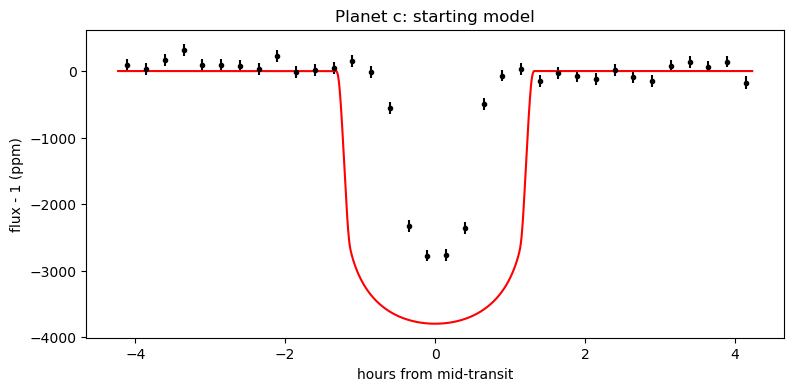

In [13]:
def bin_phase(ph, y, half, width_min=15):
    w = width_min / 1440
    edges = np.arange(-half, half + w, w)
    n, _ = np.histogram(ph, bins=edges)
    s, _ = np.histogram(ph, bins=edges, weights=y)
    c = 0.5 * (edges[1:] + edges[:-1])
    ok = n > 0
    return c[ok], s[ok] / n[ok], np.median(dy) / np.sqrt(n[ok])

ph = ((t - theta0[0] + 0.5 * theta0[1]) % theta0[1]) - 0.5 * theta0[1]
cb, fb, eb = bin_phase(ph, f, half_win)
o = np.argsort(ph)

plt.figure(figsize=(9, 4))
plt.errorbar(cb * 24, (fb - 1) * 1e6, eb * 1e6, fmt="ko", ms=3)
plt.plot(ph[o] * 24, (model(theta0)[o] - 1) * 1e6, "r-")
plt.xlabel("hours from mid-transit"); plt.ylabel("flux - 1 (ppm)")
plt.title(f"Planet {name}: starting model")
plt.show()

#### Sampling Begins

In [14]:
#Step 9: Start the walkers

scales = np.array([1e-3, 1e-5, 0.003, 0.0, 0.3 * RHO[1], 0.05, 0.05, 1e-5, 0.02])
rng = np.random.default_rng(1)
nwalk, ndim = 36, 9

p0 = []
while len(p0) < nwalk:
    cand = theta0 + scales * rng.standard_normal(ndim)
    cand[3] = rng.uniform(0.05, 0.9)                 # start b all over the range
    if np.isfinite(log_prob(cand)):
        p0.append(cand)
p0 = np.array(p0)

In [15]:
#Step 10: Run emcee once; later runs load the saved chain instead
import json

N_STEPS = 15000
h5  = f"../data/chain_{name}.h5"
cfg = f"../data/chain_{name}_settings.json"

# the setup this chain belongs to
settings = {"planet": name,
            "RHO": [float(RHO[0]), float(RHO[1])],
            "half_win_h": round(float(half_win) * 24, 3),
            "n_points": int(len(t))}

# safety check: refuse to reuse a chain made with a different setup
if os.path.exists(cfg):
    if json.load(open(cfg)) != settings:
        raise RuntimeError("Setup changed since this chain was made. "
                           "Delete the old .h5 and .json files (or rename them) to start fresh.")
else:
    json.dump(settings, open(cfg, "w"))

backend = emcee.backends.HDFBackend(h5)
done = backend.iteration if backend.initialized else 0

if done >= N_STEPS:
    print(f"{name}: chain already complete ({done} steps), not rerunning.")
else:
    if done == 0:
        backend.reset(nwalk, ndim)          # brand-new file; only reached when nothing is saved yet
        start = p0
    else:
        print(f"{name}: resuming from step {done}")
        start = None                        # None = continue from the last saved positions
    sampler = emcee.EnsembleSampler(nwalk, ndim, log_prob, backend=backend)
    sampler.run_mcmc(start, N_STEPS - done, progress=True)

c: chain already complete (15000 steps), not rerunning.


In [16]:
#Step 11.1: Checking if it converged (works even without loading the chain)

reader = emcee.backends.HDFBackend(h5, read_only=True)   # read_only: cannot modify the file
n_steps = reader.iteration
labels = ["T0", "P", "k", "b", "rho", "q1", "q2", "f0", "lns"]

tau = reader.get_autocorr_time(tol=0)
for l, tt in zip(labels, tau):
    print(l, "autocorr time:", round(tt), "| chain / tau:", round(n_steps / tt))

T0 autocorr time: 179 | chain / tau: 84
P autocorr time: 166 | chain / tau: 90
k autocorr time: 215 | chain / tau: 70
b autocorr time: 197 | chain / tau: 76
rho autocorr time: 200 | chain / tau: 75
q1 autocorr time: 346 | chain / tau: 43
q2 autocorr time: 280 | chain / tau: 53
f0 autocorr time: 178 | chain / tau: 84
lns autocorr time: 210 | chain / tau: 71


In [17]:
#Step 11.2: Breaking the chain in two parts and comparing

burn = int(3 * tau.max())
chain = reader.get_chain(discard=burn)                  # (steps, walkers, parameters)
mid = chain.shape[0] // 2

for i, l in enumerate(labels):
    h1, h2 = np.median(chain[:mid, :, i]), np.median(chain[mid:, :, i])
    print(l, "| diff / std:", round((h1 - h2) / np.std(chain[:, :, i]), 2))

thin = max(1, int(0.5 * tau.min()))
flat = reader.get_chain(discard=burn, thin=thin, flat=True)
np.save(f"../data/chain_{name}.npy", flat)
print("flat chain:", flat.shape)

T0 | diff / std: 0.01
P | diff / std: -0.0
k | diff / std: 0.03
b | diff / std: 0.0
rho | diff / std: 0.01
q1 | diff / std: 0.06
q2 | diff / std: -0.02
f0 | diff / std: 0.0
lns | diff / std: 0.0
flat chain: (6120, 9)


In [18]:
#Step 11.3: Checking if the walkers are running sensibly, or are stuck

acc = reader.accepted / reader.iteration            # fraction of accepted moves, per walker
print("mean acceptance:", round(acc.mean(), 2), "| min:", round(acc.min(), 2), "| max:", round(acc.max(), 2))

mean acceptance: 0.31 | min: 0.01 | max: 0.35


#### Results

In [19]:
#Step 12: Parameters, including derived values

def summ(x):
    lo, med, hi = np.percentile(x, [16, 50, 84])
    return med, hi - med, med - lo

T0s, Ps, ks, bs, rhos = [flat[:, i] for i in range(5)]
aRs = aRs_from_rho(rhos, Ps)
inc = np.arccos(bs / aRs)
T14s = Ps / np.pi * np.arcsin(np.sqrt((1 + ks) ** 2 - bs ** 2) / (aRs * np.sin(inc))) * 24

table = {"T0": T0s, "P": Ps, "k": ks, "b": bs, "rho": rhos, "q1": flat[:, 5], "q2": flat[:, 6],
         "depth_k2_ppm": ks ** 2 * 1e6, "a_over_Rs": aRs, "inc_deg": np.degrees(inc), "T14_h": T14s}

rows = []
for key, x in table.items():
    med, up, dn = summ(x)
    rows.append({"param": key, "median": med, "+": up, "-": dn})
fit_table = pd.DataFrame(rows)
print(fit_table.round(6).to_string(index=False))
fit_table.to_csv(f"../data/batman_{name}.csv", index=False)

       param      median          +          -
          T0 2656.279403   0.000351   0.000305
           P   16.051105   0.000006   0.000005
           k    0.057154   0.002661   0.002351
           b    0.899957   0.013461   0.019679
         rho    8.586793   1.174416   1.202611
          q1    0.294629   0.223467   0.184324
          q2    0.423297   0.371453   0.284599
depth_k2_ppm 3266.582146 311.307097 263.158522
   a_over_Rs   48.902139   2.134871   2.398724
     inc_deg   88.945695   0.076981   0.069987
       T14_h    1.398518   0.041258   0.032645


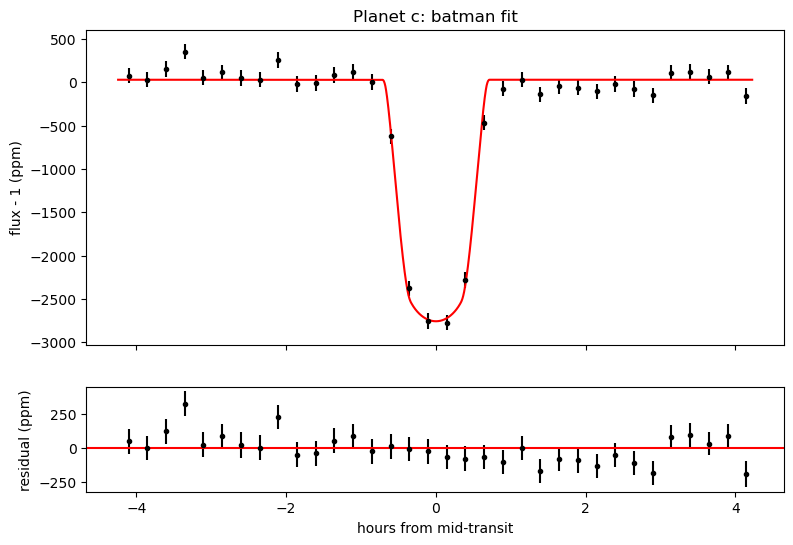

In [20]:
#Step 13: Fitted Model against Folded Data

theta_med = np.median(flat, axis=0)
ph = ((t - theta_med[0] + 0.5 * theta_med[1]) % theta_med[1]) - 0.5 * theta_med[1]
mod = model(theta_med)
o = np.argsort(ph)

cb, fb, eb = bin_phase(ph, f, half_win)
_, rb, _ = bin_phase(ph, f - mod, half_win)

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].errorbar(cb * 24, (fb - 1) * 1e6, eb * 1e6, fmt="ko", ms=3)
ax[0].plot(ph[o] * 24, (mod[o] - 1) * 1e6, "r-")
ax[0].set_ylabel("flux - 1 (ppm)"); ax[0].set_title(f"Planet {name}: batman fit")
ax[1].errorbar(cb * 24, rb * 1e6, eb * 1e6, fmt="ko", ms=3); ax[1].axhline(0, color="r")
ax[1].set_ylabel("residual (ppm)"); ax[1].set_xlabel("hours from mid-transit")
plt.show()

/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


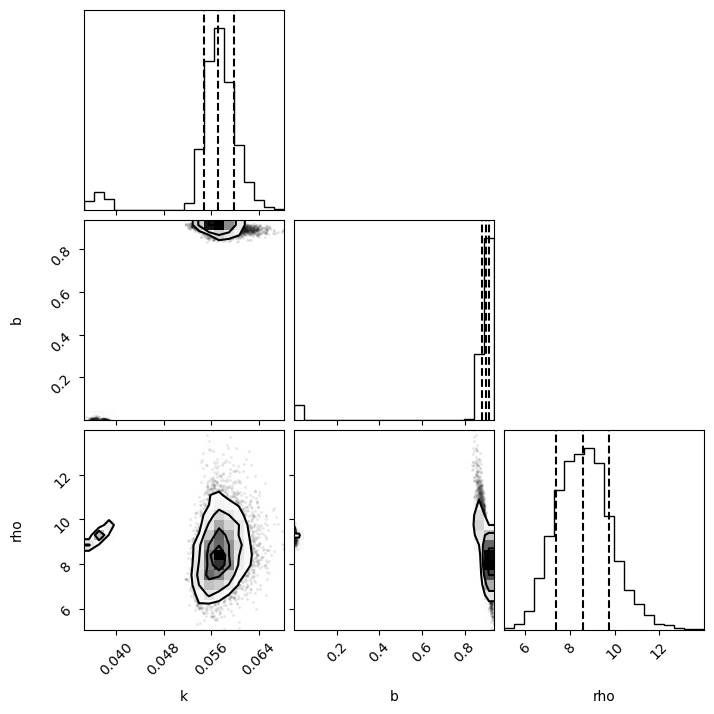

In [21]:
#Step 14: b, k and density trade off

import corner
corner.corner(np.column_stack([ks, bs, rhos]), labels=["k", "b", "rho"],
              quantiles=[0.16, 0.5, 0.84])
plt.show()

In [23]:
#Finding the stuck walkers and dropping them

acc = reader.accepted / reader.iteration
lp = reader.get_log_prob(discard=burn)                 # shape (steps, walkers)
mean_lp = lp.mean(axis=0)
print("median of the walkers' mean log_prob:", round(np.median(mean_lp), 1))
for w in np.argsort(acc)[:5]:
    print(f"walker {w:2d}: acceptance {acc[w]:.2f} | mean log_prob {mean_lp[w]:.1f}")

median of the walkers' mean log_prob: 68852.5
walker 25: acceptance 0.01 | mean log_prob 68009.1
walker 32: acceptance 0.02 | mean log_prob 68007.8
walker 22: acceptance 0.31 | mean log_prob 68852.8
walker  1: acceptance 0.32 | mean log_prob 68852.6
walker  5: acceptance 0.32 | mean log_prob 68852.7


In [24]:
#Keeping walkers only with high acceptance rate

good = (acc > 0.1) & (mean_lp > np.median(mean_lp) - 10)
print("keeping", good.sum(), "of", len(good), "walkers")

chain_all = reader.get_chain(discard=burn, thin=thin)   # (steps, walkers, parameters)
flat = chain_all[:, good, :].reshape(-1, chain_all.shape[2])
np.save(f"../data/chain_{name}.npy", flat)
print("flat chain:", flat.shape)

keeping 34 of 36 walkers
flat chain: (5780, 9)


#### Rerunning the results with eliminated chains

In [25]:
#Step 12: Parameters, including derived values

def summ(x):
    lo, med, hi = np.percentile(x, [16, 50, 84])
    return med, hi - med, med - lo

T0s, Ps, ks, bs, rhos = [flat[:, i] for i in range(5)]
aRs = aRs_from_rho(rhos, Ps)
inc = np.arccos(bs / aRs)
T14s = Ps / np.pi * np.arcsin(np.sqrt((1 + ks) ** 2 - bs ** 2) / (aRs * np.sin(inc))) * 24

table = {"T0": T0s, "P": Ps, "k": ks, "b": bs, "rho": rhos, "q1": flat[:, 5], "q2": flat[:, 6],
         "depth_k2_ppm": ks ** 2 * 1e6, "a_over_Rs": aRs, "inc_deg": np.degrees(inc), "T14_h": T14s}

rows = []
for key, x in table.items():
    med, up, dn = summ(x)
    rows.append({"param": key, "median": med, "+": up, "-": dn})
fit_table = pd.DataFrame(rows)
print(fit_table.round(6).to_string(index=False))
fit_table.to_csv(f"../data/batman_{name}.csv", index=False)

       param      median          +          -
          T0 2656.279380   0.000303   0.000294
           P   16.051105   0.000005   0.000005
           k    0.057335   0.002594   0.002078
           b    0.901087   0.012760   0.016578
         rho    8.488446   1.325157   1.138611
          q1    0.278570   0.249939   0.173185
          q2    0.454253   0.351463   0.323487
depth_k2_ppm 3287.341883 304.165905 233.993344
   a_over_Rs   48.714738   2.413438   2.283525
     inc_deg   88.940880   0.067073   0.067339
       T14_h    1.395978   0.035135   0.031237


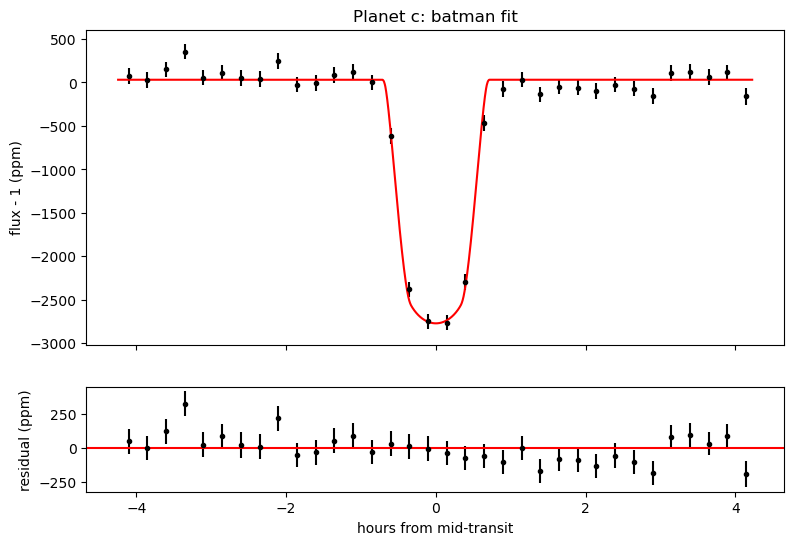

In [26]:
#Step 13: Fitted Model against Folded Data

theta_med = np.median(flat, axis=0)
ph = ((t - theta_med[0] + 0.5 * theta_med[1]) % theta_med[1]) - 0.5 * theta_med[1]
mod = model(theta_med)
o = np.argsort(ph)

cb, fb, eb = bin_phase(ph, f, half_win)
_, rb, _ = bin_phase(ph, f - mod, half_win)

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].errorbar(cb * 24, (fb - 1) * 1e6, eb * 1e6, fmt="ko", ms=3)
ax[0].plot(ph[o] * 24, (mod[o] - 1) * 1e6, "r-")
ax[0].set_ylabel("flux - 1 (ppm)"); ax[0].set_title(f"Planet {name}: batman fit")
ax[1].errorbar(cb * 24, rb * 1e6, eb * 1e6, fmt="ko", ms=3); ax[1].axhline(0, color="r")
ax[1].set_ylabel("residual (ppm)"); ax[1].set_xlabel("hours from mid-transit")
plt.show()

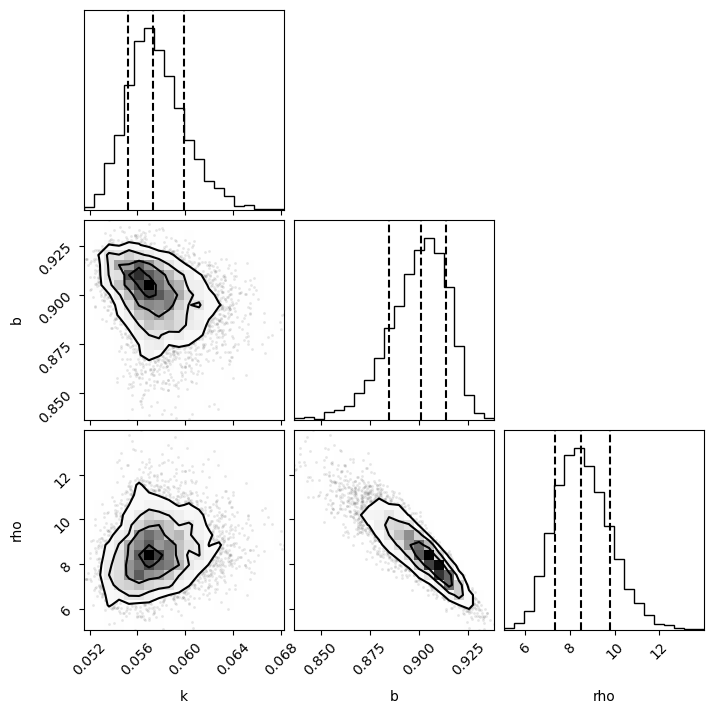

In [27]:
#Step 14: b, k and density trade off

import corner
corner.corner(np.column_stack([ks, bs, rhos]), labels=["k", "b", "rho"],
              quantiles=[0.16, 0.5, 0.84])
plt.show()

In [29]:
#Recomputing tau

chain_good = reader.get_chain(discard=burn)[:, good, :]
tau_good = emcee.autocorr.integrated_time(chain_good, tol=0)
n_good = chain_good.shape[0]
for l, tt in zip(labels, tau_good):
    print(l, "tau:", round(tt), "| chain / tau:", round(n_good / tt))

T0 tau: 170 | chain / tau: 82
P tau: 154 | chain / tau: 91
k tau: 210 | chain / tau: 66
b tau: 279 | chain / tau: 50
rho tau: 202 | chain / tau: 69
q1 tau: 319 | chain / tau: 44
q2 tau: 265 | chain / tau: 53
f0 tau: 158 | chain / tau: 88
lns tau: 193 | chain / tau: 72
